# Regresja liniowa

Iteracja 0, koszt: 3155.639662763719, w0: 0.08581153846153845, w1: 4.936269230769231
Iteracja 20000, koszt: 1878.6953036982059, w0: 85.2367626634799, w1: 3.4023068213029104
Iteracja 40000, koszt: 1463.5131526917082, w0: 134.53447772524464, w1: 2.6005307166771776
Iteracja 60000, koszt: 1324.3614501709312, w0: 163.07432962601692, w1: 2.1363596845121546
Iteracja 80000, koszt: 1277.7236159878132, w0: 179.59686308416042, w1: 1.867637848256233
Iteracja 100000, koszt: 1262.0925634179227, w0: 189.16222848355451, w1: 1.7120671204924982
Iteracja 120000, koszt: 1256.853687970077, w0: 194.69989106149347, w1: 1.6220027934763515
Iteracja 140000, koszt: 1255.0978359034727, w0: 197.90580171379835, w1: 1.5698619883424285
Iteracja 160000, koszt: 1254.5093476848674, w0: 199.76179473719094, w1: 1.5396761905900616
Iteracja 180000, koszt: 1254.312111032632, w0: 200.83628198168518, w1: 1.522200772180075


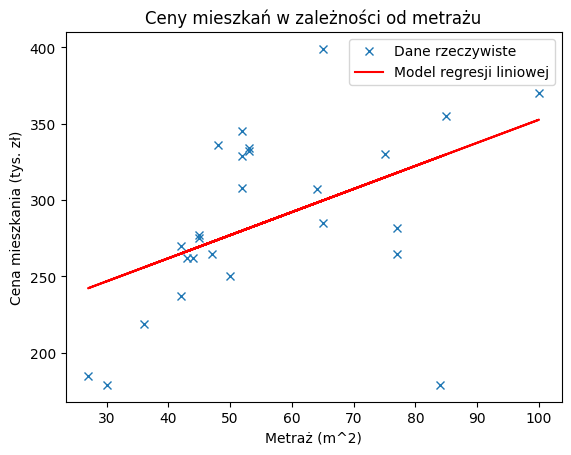

Wyznaczone wartości wag -> w0: 201.4583098897398, w1: 1.5120841346754017


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Załaduj dane
sizes = np.loadtxt('flat.areas').reshape((26, 1))  # Wektor rozmiarów mieszkań
prices = np.loadtxt('flat.prices').reshape((26, 1))  # Wektor cen mieszkań
samples_cnt = len(prices)  # Liczba próbek

# Inicjalizacja wag i parametrów
weight0 = 0.0  # Wyraz wolny
weight1 = 0.0  # Waga cechy
learning_rate = 0.0003  # Stała uczenia
maxIteration = 200000  # Liczba iteracji

# Funkcja kosztu (Mean Squared Error - MSE)
def compute_cost(sizes, prices, weight0, weight1):
    m = len(prices)
    predictions = weight0 + weight1 * sizes
    cost = (1 / (2 * m)) * np.sum((predictions - prices) ** 2)
    return cost

# Spadek gradientowy
cost_history = []  # Historia wartości funkcji kosztu dla każdej iteracji

for i in range(maxIteration):
    # Obliczanie przewidywanych cen
    predictions = weight0 + weight1 * sizes
    
    # Obliczanie błędu
    error = predictions - prices
    
    # Obliczanie gradientów
    gradient_w0 = (1 / samples_cnt) * np.sum(error)
    gradient_w1 = (1 / samples_cnt) * np.sum(error * sizes)
    
    # Aktualizacja wag
    weight0 -= learning_rate * gradient_w0
    weight1 -= learning_rate * gradient_w1
    
    # Obliczanie i zapisywanie wartości funkcji kosztu
    cost = compute_cost(sizes, prices, weight0, weight1)
    cost_history.append(cost)
    
    # Co jakiś czas możemy wypisywać postęp, np. co 1000 iteracji
    if i % 20000 == 0:
        print(f"Iteracja {i}, koszt: {cost}, w0: {weight0}, w1: {weight1}")

# Wykres
plt.plot(sizes, prices, "x", label="Dane rzeczywiste")
plt.plot(sizes, weight0 + weight1 * sizes, "r-", label="Model regresji liniowej")
plt.title('Ceny mieszkań w zależności od metrażu')
plt.xlabel('Metraż (m^2)')
plt.ylabel('Cena mieszkania (tys. zł)')
plt.legend()
plt.show()

# Wypisanie końcowych wartości wag
print(f"Wyznaczone wartości wag -> w0: {weight0}, w1: {weight1}")


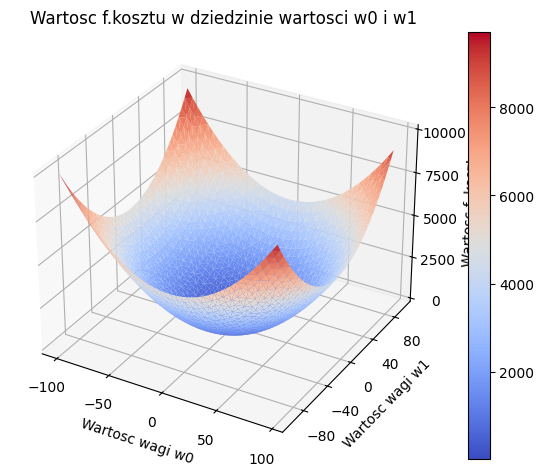

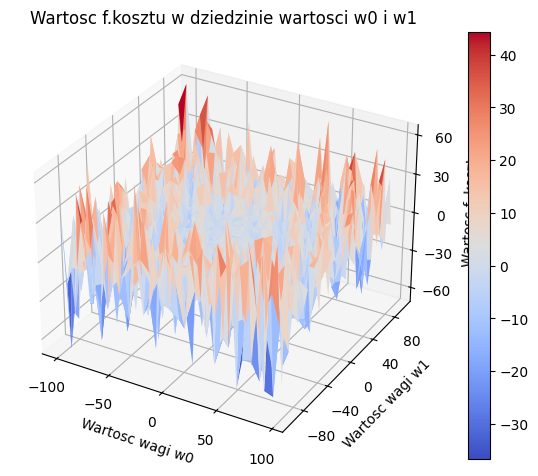

In [2]:
from helpers import visualize_cost_function
import numpy as np

def loss_function(sizes, prices, weight0, weight1):
    predictions = [weight0 + weight1*sizes[i] for i in range(len(prices))]
    return sum([(predictions[i] - prices[i])**2 for i in range(len(prices))])/(2*len(prices))


def loss_function2(sizes, prices, weight0, weight1):
    predictions = [weight0 + weight1*sizes[i] for i in range(len(prices))]
    return sum([(np.sin(predictions[i]/prices[i]**2) * (predictions[i]*prices[i]**3)) for i in range(len(prices))])/(2*len(prices))


#Poniższy kod wyznacza wartości funkcji kosztu w dziedzinie wartości atrybutów w0 i w1
w0_values = np.arange(-10, 10, 0.5)
w1_values = np.arange(-10, 10, 0.5)

sizes_transformed = ((sizes - np.mean(sizes)) / np.std(sizes)).reshape(-1)
prices_transformed = ((prices - np.mean(prices)) / np.std(prices)).reshape(-1)

w0_values = np.arange(-100, 100, 5)
w1_values = np.arange(-100, 100, 5)

visualize_cost_function(sizes_transformed, prices_transformed, w0_values, w1_values, loss_function)
visualize_cost_function(sizes_transformed, prices_transformed, w0_values, w1_values, loss_function2)

# Regresja wielomianowa

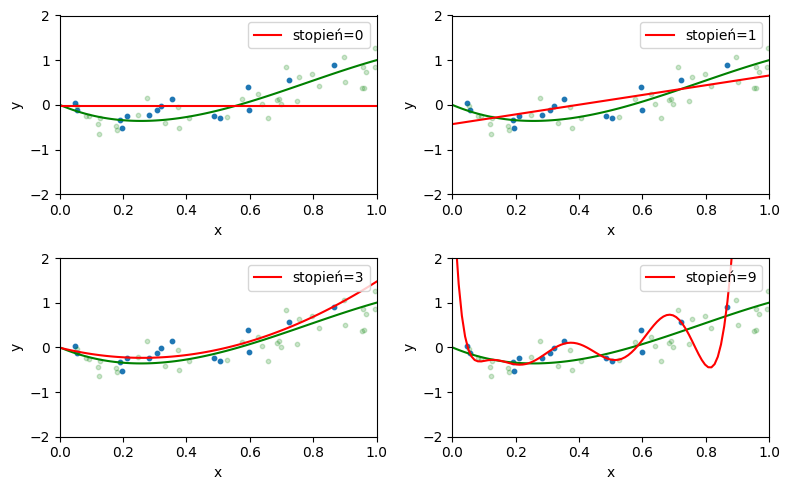

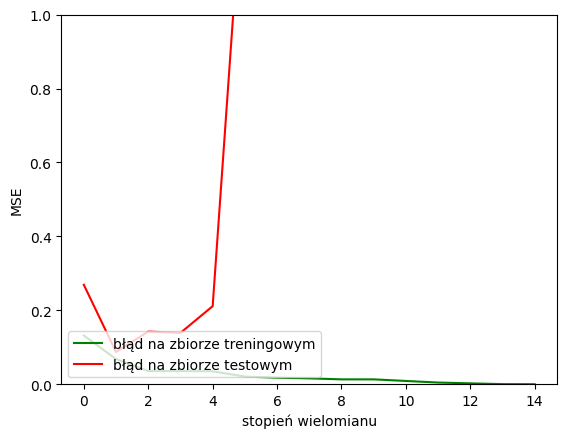

In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split # model_selection w starszych wersjach -> cross_validation
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

#funkcja, ktora chcemy aproksymowac
def f(x): 
	return -(3*x)+(7*x**2)-(3*x**3)

x = np.linspace(0,1,100) #Stworzenie przestrzeni w której będziemy wizualizować aproksymowaną funkcję (x od 0 do 1 z krokiem 1/100)

X = np.random.uniform(0, 1, size=50)[:, np.newaxis] #Wylosowanie przykladow (os X)
y = f(X) + np.random.normal(scale=0.3, size=50)[:, np.newaxis] #Wygenerowanie punktów zgodnie z funkcją f(x) z uwzględnieniem szumu

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.7) #Podzial danych na zbior treningowy i testowy


#Pomocnicza funkcja do wizualizacji
def plot_approximation(est, ax, label=None):
    ax.plot(x, f(x), color='green')
    ax.scatter(X_train, y_train, s=10) #Dodanie punktow zbioru treningowego do wizualizacji
    ax.scatter(X_test, y_test, s=10, color='green', alpha=0.2) #Dodanie punktow zbioru testowego do wizualizacji
    ax.plot(x, est.predict(x[:, np.newaxis]), color='red', label=label) #Wizualizacja wygenerowanej funkcji
    ax.set_ylim((-2, 2))
    ax.set_xlim((0, 1))
    ax.set_ylabel('y')
    ax.set_xlabel('x')
    ax.legend(loc='upper right')

#Uzycie sklearn do wygenerowania regresji wielomianowej stopnia 0,1,3,9
fig, axes = plt.subplots(2, 2, figsize=(8, 5))
for ax, degree in zip(axes.ravel(), [0, 1, 3, 9]):
    est = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    est.fit(X_train, y_train)
    plot_approximation(est, ax, label='stopień=%d' % degree)
plt.tight_layout()
plt.show()


#Uzycie sklearn do wygenerowania regresji wielomianowej stopnia 0..15, w celu weryfikacji bledu na zbiorach uczacym i testowym
train_error = np.empty(15)
test_error = np.empty(15)
for degree in range(15):
    est = make_pipeline(PolynomialFeatures(degree), LinearRegression()) #Zdefiniowanie typu modelu
    est.fit(X_train, y_train)  #Uczenie parametrów
    train_error[degree] = mean_squared_error(y_train, est.predict(X_train)) #Zapisanie bledu zb. uczacego dla zadanego stopnia wielomianu
    test_error[degree] = mean_squared_error(y_test, est.predict(X_test)) #Zapisanie bledu zb. testowego dla zadanego stopnia wielomianu
    
    
#Wizualizacja bledu. Odpowiednio na zbiorze uczacym i testowym
plt.plot(np.arange(15), train_error, color='green', label='błąd na zbiorze treningowym')
plt.plot(np.arange(15), test_error, color='red', label='błąd na zbiorze testowym')
plt.legend(loc = 'upper right')
plt.ylim((0.0, 1e0))
plt.ylabel('MSE')
plt.xlabel('stopień wielomianu')
plt.legend(loc='lower left')
plt.show()

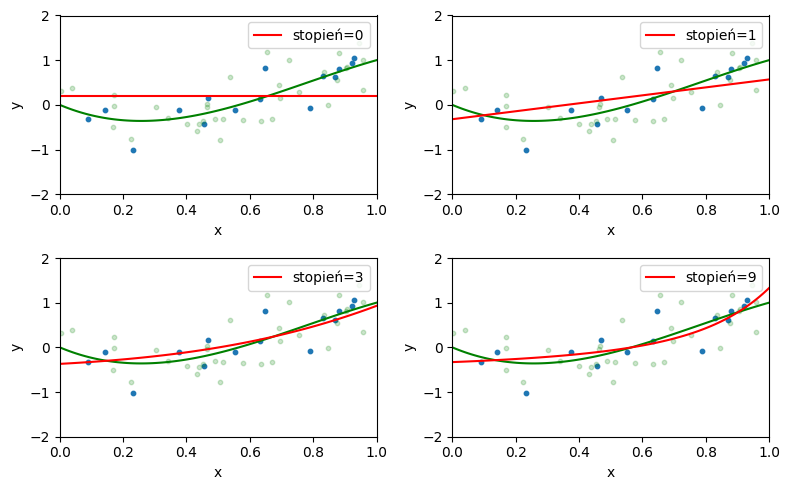

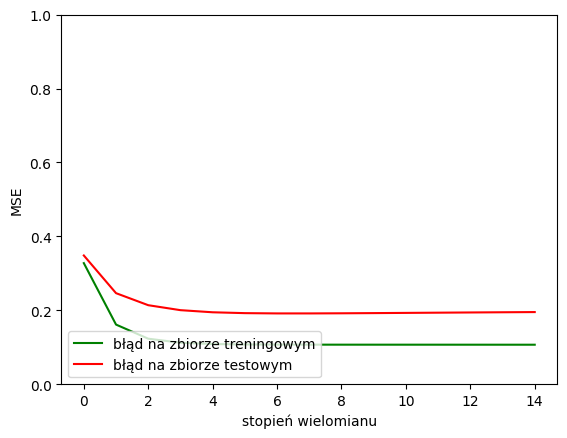

In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split # model_selection w starszych wersjach -> cross_validation
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

#funkcja, ktora chcemy aproksymowac
def f(x): 
	return -(3*x)+(7*x**2)-(3*x**3)

x = np.linspace(0,1,100) #Stworzenie przestrzeni w której będziemy wizualizować aproksymowaną funkcję (x od 0 do 1 z krokiem 1/100)

X = np.random.uniform(0, 1, size=50)[:, np.newaxis] #Wylosowanie przykladow (os X)
y = f(X) + np.random.normal(scale=0.3, size=50)[:, np.newaxis] #Wygenerowanie punktów zgodnie z funkcją f(x) z uwzględnieniem szumu

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.7) #Podzial danych na zbior treningowy i testowy


#Pomocnicza funkcja do wizualizacji
def plot_approximation(est, ax, label=None):
    ax.plot(x, f(x), color='green')
    ax.scatter(X_train, y_train, s=10) #Dodanie punktow zbioru treningowego do wizualizacji
    ax.scatter(X_test, y_test, s=10, color='green', alpha=0.2) #Dodanie punktow zbioru testowego do wizualizacji
    ax.plot(x, est.predict(x[:, np.newaxis]), color='red', label=label) #Wizualizacja wygenerowanej funkcji
    ax.set_ylim((-2, 2))
    ax.set_xlim((0, 1))
    ax.set_ylabel('y')
    ax.set_xlabel('x')
    ax.legend(loc='upper right')

#Uzycie sklearn do wygenerowania regresji wielomianowej stopnia 0,1,3,9
fig, axes = plt.subplots(2, 2, figsize=(8, 5))
for ax, degree in zip(axes.ravel(), [0, 1, 3, 9]):
    est = make_pipeline(PolynomialFeatures(degree), Ridge())
    est.fit(X_train, y_train)
    plot_approximation(est, ax, label='stopień=%d' % degree)
plt.tight_layout()
plt.show()


#Uzycie sklearn do wygenerowania regresji wielomianowej stopnia 0..15, w celu weryfikacji bledu na zbiorach uczacym i testowym
train_error = np.empty(15)
test_error = np.empty(15)
for degree in range(15):
    est = make_pipeline(PolynomialFeatures(degree), Ridge()) #Zdefiniowanie typu modelu
    est.fit(X_train, y_train)  #Uczenie parametrów
    train_error[degree] = mean_squared_error(y_train, est.predict(X_train)) #Zapisanie bledu zb. uczacego dla zadanego stopnia wielomianu
    test_error[degree] = mean_squared_error(y_test, est.predict(X_test)) #Zapisanie bledu zb. testowego dla zadanego stopnia wielomianu
    
    
#Wizualizacja bledu. Odpowiednio na zbiorze uczacym i testowym
plt.plot(np.arange(15), train_error, color='green', label='błąd na zbiorze treningowym')
plt.plot(np.arange(15), test_error, color='red', label='błąd na zbiorze testowym')
plt.legend(loc = 'upper right')
plt.ylim((0.0, 1e0))
plt.ylabel('MSE')
plt.xlabel('stopień wielomianu')
plt.legend(loc='lower left')
plt.show()